<a href="https://colab.research.google.com/github/mayajdias/walmart-hurricane-project/blob/main/notebooks/scratch/Question4_Question5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Q4 & Q5: Store Geography and the Board Games Investigation

This is a working notebook. Parts 0–1 rebuild Nate's cleaned tables so this notebook can run on its own.
Only Parts 2–4 (Q4 and Q5) get copied into the team notebook.

## Part 0: Setup

In [1]:
import os
if not os.path.exists('walmart-hurricane-project'):
    !git clone -q https://github.com/mayajdias/walmart-hurricane-project.git
DATA = 'walmart-hurricane-project/data/'
print(sorted(os.listdir(DATA)))

['distribution_centers.csv', 'inventory_and_sales.db', 'product_catalog (1).csv', 'store_locations.csv', 'walmart_transactions.csv']


## Part 1: Cleaning (this was copied from Nate's scratch/Cleaning.ipynb)

In [2]:
import pandas as pd, numpy as np, sqlite3

canonical_sku_groups = {
    'POPTART-STRAW': ['PT-12', 'SKU#459812', 'PT_STRAWBERRY'],
    'SOUP-CAN': ['CNSOUP-01'], 'BG-MONO': ['GAME-MONO', 'MONOPOLY-01'],
    'BEER-24': ['LTBEER24'], 'WTR-24': ['WTR_24PK', 'WATER24PK'],
    'CANDLE-EMRG': ['CNDL-EM'], 'TARP-HD': ['HDTARP-01'], 'LED-FLASH': ['FLASH-01'],
    'CHRG-PORT': ['PORTCHARGER'], 'FIRSTAID-KIT': ['FAID-01'], 'ROKU-STD': ['STREAM-01'],
    'PTOWEL-6': ['PAPERTOWEL6'], 'PLAYCARD-STD': ['CARDS-01'], 'BREAD-WH': ['WHITEBREAD'],
    'TOILETPAPER12': ['TP-12'], 'PNUTBTR-16': ['PB-16'], 'BABYFORMULA': ['BFORM-01'],
    'DIAPERS-3': ['DIAP-S3'], 'BAT-AA4': ['BATT-100', 'BATT_AA_4PK'], 'CHIPVARIETY': ['CHIPS-VP'],
}
sku_mapping = {o: t for t, os_ in canonical_sku_groups.items() for o in os_}

canonical_category_groups = {
    'Emergency': ['EMERGENCY', 'Emergency Supplies', 'emergency'],
    'Grocery': ['Groceries', 'grocery', 'GROCERY'],
    'Electronics': ['electronics', 'ELECTRONICS'],
    'Entertainment': ['Games & Entertainment', 'entertainment', 'ENTERTAINMENT'],
    'Household': ['HOUSEHOLD', 'household', 'Household Essentials'],
    'Baby': ['baby', 'BABY', 'Baby Products'],
    'Breakfast': ['breakfast', 'BREAKFAST', 'Breakfast Foods'],
    'Alcohol': ['ALCOHOL', 'Alcoholic Beverages'],
    'Snacks': ['snacks', 'SNACKS'],
    'Health': ['HEALTH', 'health', 'Health & Wellness'],
}
category_mapping = {o: t for t, os_ in canonical_category_groups.items() for o in os_}

def clean_store_id(s):
    return s.astype(str).str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)

# transactions
tx_raw = pd.read_csv(DATA + 'walmart_transactions.csv')
tx = tx_raw.copy()
tx['canonical_sku'] = tx['sku'].map(sku_mapping).fillna(tx['sku'])
tx['canonical_category'] = tx['category'].map(category_mapping).fillna(tx['category'])
tx['store_id'] = clean_store_id(tx['store_id'])
tx['unit_price'] = tx['unit_price'].astype(str).str.replace(r'[^\d.]', '', regex=True).astype(float)
tx = tx.drop_duplicates()
tx['timestamp'] = pd.to_datetime(tx['timestamp'], format='mixed', errors='coerce')
tx = tx.dropna(subset=['timestamp'])
tx['quantity'] = tx['quantity'].abs()
walmart_transactions_cleaned = tx.reset_index(drop=True)

# stores
stores = pd.read_csv(DATA + 'store_locations.csv')
stores['store_id'] = clean_store_id(stores['store_id'])
stores['state'] = 'FL'
stores['latitude'] = stores['latitude'].fillna(30.4383)
stores['longitude'] = stores['longitude'].fillna(-84.2807)
stores_cleaned = stores.drop_duplicates(subset='store_id').reset_index(drop=True)

# SQLite
conn = sqlite3.connect(DATA + 'inventory_and_sales.db')
ds = pd.read_sql_query('SELECT * FROM daily_sales_summary', conn)
ds['store_id'] = clean_store_id(ds['store_id'])
ds['total_revenue'] = ds['total_revenue'].abs()
ds['date'] = pd.to_datetime(ds['date'], format='mixed')
daily_sales_clean = ds.drop_duplicates()

inv = pd.read_sql_query('SELECT * FROM inventory_levels', conn)
inv['store_id'] = clean_store_id(inv['store_id'])
inv['units_on_order'] = inv['units_on_order'].fillna(0).astype(int)
inv['canonical_sku'] = inv['sku'].map(sku_mapping).fillna(inv['sku'])
inv['date'] = pd.to_datetime(inv['date'], format='mixed')
inventory_clean = inv.drop_duplicates()

print('transactions:', len(walmart_transactions_cleaned), '| stores:', len(stores_cleaned),
      '| daily_sales:', len(daily_sales_clean), '| inventory:', len(inventory_clean))

transactions: 24648 | stores: 12 | daily_sales: 3600 | inventory: 4320


In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

LANDFALL       = pd.Timestamp('2024-09-26')
BASELINE_START = pd.Timestamp('2024-09-01')
BASELINE_END   = pd.Timestamp('2024-09-18')
SURGE_START    = LANDFALL - pd.Timedelta(days=7)          # Sept 19
SURGE_END      = LANDFALL - pd.Timedelta(days=1)          # Sept 25
LANDFALL_LAT, LANDFALL_LON = 30.10, -83.58                # Helene landfall, near Perry FL

NAVY, ORANGE, GREY, LIGHT = '#1f3b63', '#e07b24', '#9aa3ad', '#d9dee4'
plt.rcParams.update({
    'figure.figsize': (10, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 11, 'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False,
})

def in_window(dates, start, end):
    return (dates >= start) & (dates <= end)

def mark_landfall(ax, label=True):
    ax.axvline(LANDFALL, color=GREY, ls='--', lw=1.2)
    if label:
        ax.annotate('Helene landfall', xy=(LANDFALL, 1), xycoords=('data', 'axes fraction'),
                    xytext=(4, -14), textcoords='offset points', fontsize=9, color='#555')

def format_dates(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

print(f'Baseline: {BASELINE_START:%b %d}–{BASELINE_END:%b %d} | Surge: {SURGE_START:%b %d}–{SURGE_END:%b %d} | Landfall: {LANDFALL:%b %d}')

Baseline: Sep 01–Sep 18 | Surge: Sep 19–Sep 25 | Landfall: Sep 26


## Q4: Store-Level Geographic Patterns

 *Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.*

**Method.**
For each store, we compute three different values based on the clean data of all its transactions.

1. **Surge Multiple**: The value is calculated as the Average Daily Units during the Surge Window divided by the Average Daily Units during the Baseline Window. This represents how large the increase in the number of units was for the store.
2. **Surge Start**: We calculate this by finding the first date after September 10 where the number of daily units at a given store exceeds 150% of what the store’s baseline is. This is the earliest date that the store saw an increase in units due to Hurricane Helene.
3. **Peak Day:** The peak day is defined as the date when there were the most units sold at a store.

Lastly, we join our previous results with stores_cleaned and find out how far each store is away from Helene’s Landfall Point

In [4]:
tx = walmart_transactions_cleaned.copy()
tx['date'] = tx['timestamp'].dt.normalize()

store_daily = tx.groupby(['date', 'store_id'])['quantity'].sum().unstack(fill_value=0)

baseline = store_daily[in_window(store_daily.index, BASELINE_START, BASELINE_END)].mean()
surge    = store_daily[in_window(store_daily.index, SURGE_START, SURGE_END)].mean()
after10  = store_daily[store_daily.index >= pd.Timestamp('2024-09-10')]

store_surge = pd.DataFrame({
    'baseline_units_per_day': baseline.round(1),
    'surge_units_per_day': surge.round(1),
    'surge_multiple': (surge / baseline).round(2),
    'surge_start': after10.gt(1.5 * baseline).idxmax(),
    'peak_day': store_daily.idxmax(),
    'transactions': tx['store_id'].value_counts(),
}).rename_axis('store_id').reset_index()

rows_before = len(store_surge)
store_surge = store_surge.merge(stores_cleaned[['store_id', 'city', 'region', 'latitude', 'longitude']],
                                on='store_id', how='left', validate='one_to_one')
assert len(store_surge) == rows_before and store_surge['city'].notna().all(), 'store join lost or duplicated rows'

store_surge['miles_to_landfall'] = haversine_miles(store_surge['latitude'], store_surge['longitude'],
                                                   LANDFALL_LAT, LANDFALL_LON).round(0).astype(int)
store_surge['days_before_landfall'] = (LANDFALL - store_surge['surge_start']).dt.days
store_surge = store_surge.sort_values('miles_to_landfall').reset_index(drop=True)

print(f'Rows before join: {rows_before} | after join: {len(store_surge)}')
store_surge[['store_id', 'city', 'region', 'miles_to_landfall', 'baseline_units_per_day',
             'surge_units_per_day', 'surge_multiple', 'surge_start', 'days_before_landfall', 'peak_day']]

Rows before join: 12 | after join: 12


,store_id,city,region,miles_to_landfall,baseline_units_per_day,surge_units_per_day,surge_multiple,surge_start,days_before_landfall,peak_day
0,FL619,Tallahassee,Panhandle,48,94.6,225.9,2.39,2024-09-20,6,2024-09-24
1,FL078,Gainesville,North,81,98.3,221.0,2.25,2024-09-21,5,2024-09-25
2,FL412,Jacksonville,North,116,95.9,224.3,2.34,2024-09-21,5,2024-09-25
3,FL105,Tampa,West,163,98.6,232.1,2.35,2024-09-21,5,2024-09-25
4,FL156,Daytona Beach,East,165,99.0,229.7,2.32,2024-09-21,5,2024-09-24
5,FL239,Orlando,Central,171,98.8,210.1,2.13,2024-09-21,5,2024-09-24
6,FL445,St. Petersburg,West,171,101.4,232.6,2.29,2024-09-21,5,2024-09-24
7,FL302,Lakeland,Central,173,102.8,239.6,2.33,2024-09-21,5,2024-09-25
8,FL287,Kissimmee,Central,181,97.8,221.6,2.26,2024-09-21,5,2024-09-25
9,FL710,Pensacola,Panhandle,218,98.9,229.3,2.32,2024-09-21,5,2024-09-25


In [5]:
r = store_surge['miles_to_landfall'].corr(store_surge['surge_multiple'])
z = (store_surge['surge_multiple'] - store_surge['surge_multiple'].mean()) / store_surge['surge_multiple'].std()
store_surge['z_score'] = z.round(2)

print(f'Correlation between distance and surge multiple: r = {r:.2f}  (n = {len(store_surge)} stores)')
print(f"Surge multiple range: {store_surge['surge_multiple'].min()}x – {store_surge['surge_multiple'].max()}x")
print()
print('Stores sorted by how unusual their surge was (z-score):')
store_surge.assign(abs_z=z.abs()).sort_values(['abs_z'], ascending=False)[
    ['store_id', 'city', 'miles_to_landfall', 'surge_multiple', 'z_score', 'surge_start']].head(4)

Correlation between distance and surge multiple: r = 0.19  (n = 12 stores)
Surge multiple range: 2.13x – 2.43x

Stores sorted by how unusual their surge was (z-score):


,store_id,city,miles_to_landfall,surge_multiple,z_score,surge_start
5,FL239,Orlando,171,2.13,-2.31,2024-09-21
11,FL330,Miami,364,2.43,1.61,2024-09-18
0,FL619,Tallahassee,48,2.39,1.09,2024-09-20
1,FL078,Gainesville,81,2.25,-0.74,2024-09-21


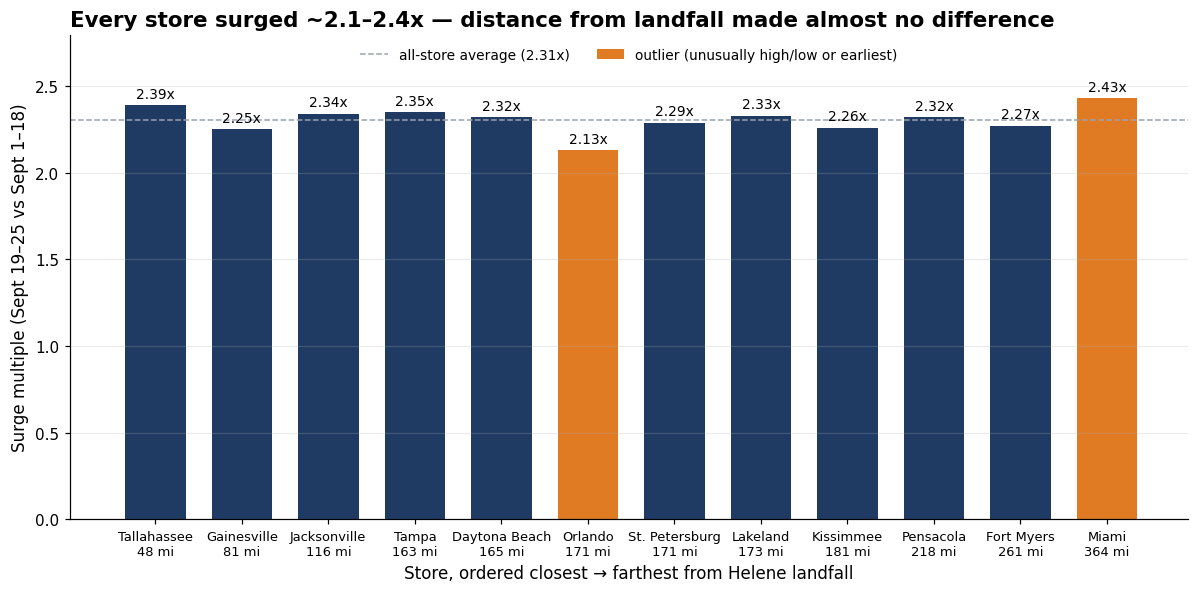

In [6]:
# CHART Q4a, surge multiple by store, ordered closest -> farthest from landfall
outlier_ids = store_surge.loc[store_surge['z_score'].abs() >= 1.5, 'store_id'].tolist()
earliest_id = store_surge.loc[store_surge['surge_start'].idxmin(), 'store_id']
highlight = set(outlier_ids) | {earliest_id}

fig, ax = plt.subplots(figsize=(11, 5.5))
labels = [f"{c}\n{m} mi" for c, m in zip(store_surge['city'], store_surge['miles_to_landfall'])]
colors = [ORANGE if s in highlight else NAVY for s in store_surge['store_id']]
bars = ax.bar(labels, store_surge['surge_multiple'], color=colors, width=0.7)
ax.bar_label(bars, labels=[f'{v:.2f}x' for v in store_surge['surge_multiple']], padding=3, fontsize=9)
ax.axhline(store_surge['surge_multiple'].mean(), color=GREY, ls='--', lw=1,
           label=f"all-store average ({store_surge['surge_multiple'].mean():.2f}x)")
ax.bar(0, 0, color=ORANGE, label='outlier (unusually high/low or earliest)')
ax.legend(loc='upper center', ncol=2, fontsize=9)

ax.set_ylim(0, store_surge['surge_multiple'].max() * 1.15)
ax.set_title('Every store surged ~2.1–2.4x — distance from landfall made almost no difference')
ax.set_ylabel('Surge multiple (Sept 19–25 vs Sept 1–18)')
ax.set_xlabel('Store, ordered closest → farthest from Helene landfall')
ax.tick_params(axis='x', labelsize=8.5)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

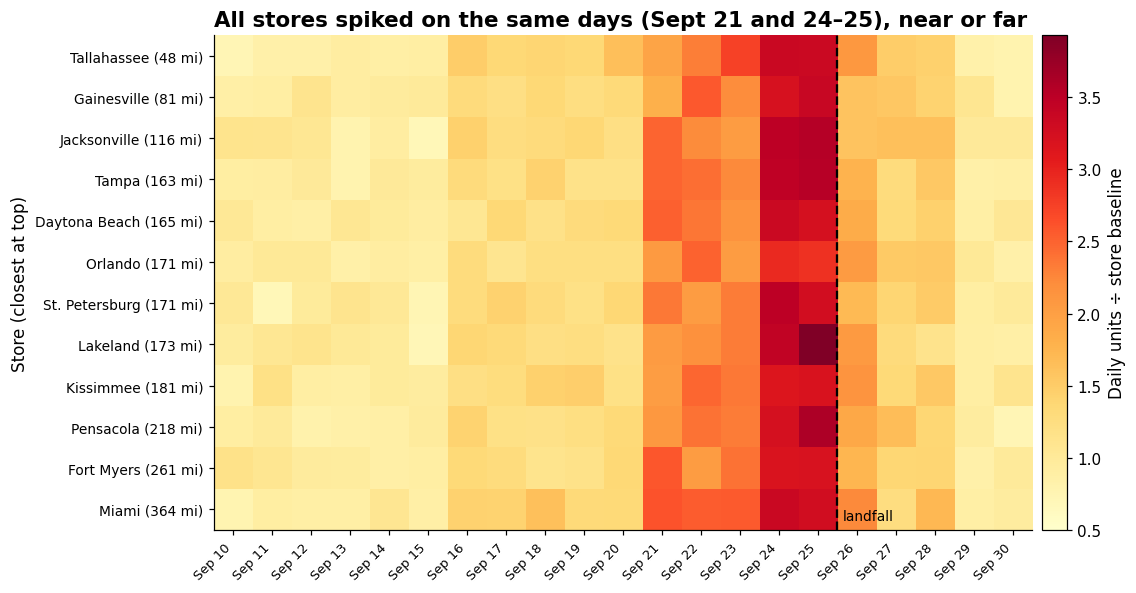

In [7]:
# CHART Q4b:timing: each store's daily units as a multiple of its own baseline
indexed = (store_daily / baseline)[store_surge['store_id']]
indexed = indexed[indexed.index >= pd.Timestamp('2024-09-10')]

fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(indexed.T.values, aspect='auto', cmap='YlOrRd', vmin=0.5, vmax=indexed.values.max())
ax.set_yticks(range(len(store_surge)))
ax.set_yticklabels([f"{c} ({m} mi)" for c, m in zip(store_surge['city'], store_surge['miles_to_landfall'])], fontsize=9)
ax.set_xticks(range(len(indexed.index)))
ax.set_xticklabels([d.strftime('%b %d') for d in indexed.index], rotation=45, ha='right', fontsize=8.5)
lf = list(indexed.index).index(LANDFALL)
ax.axvline(lf - 0.5, color='black', lw=1.5, ls='--')
ax.text(lf - 0.35, len(store_surge) - 0.75, 'landfall', fontsize=9, color='black')
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label('Daily units ÷ store baseline')
ax.set_title('All stores spiked on the same days (Sept 21 and 24–25), near or far')
ax.set_ylabel('Store (closest at top)')
plt.tight_layout()
plt.show()

### Q4 Answer

In reality there is almost no difference in the rate of increase in sales at each store. All twelve stores increased their normal daily sales by a range of **2.13 to 2.43 times**. The proximity of the landfall did not indicate how large an increase would be. In fact the relationship was weak, **r = 0.19 (n = 12)**, and actually had a slight bias toward larger increases as the stores got farther from the center. In addition, timing was nearly identical. At nearly all of the stores sales increased to over one and one half times the normal baseline on **September 21** and reached peak levels on either **September 24 or 25** regardless of location. The stores are located at distances ranging from 48 miles (Tallahassee) to 364 miles (Miami) from the center.

**The outliers were:**
- **Miami (FL330):** It was the store that was the furthest from the center (364 mi) but it experienced the largest increase in sales (**2.43x**) and started its run-up in sales three days before most other stores began theirs (**Sept 18**). Our belief is that consumers in South Florida respond to the forecast cone, which covers much of Florida, rather than to the eventual landfall track.
- **Orlando (FL239):** This store had the smallest increase in sales (**2.13x**) and was more than two standard deviations below the mean (**z = −2.31**) despite being closer to the center of the storm (171 miles) than some of the other stores.
- **Tallahassee (FL619):** Although it was the closest store (48 miles) to the center and started increasing its sales a day before most other stores (**Sept 20**), it did not have an increase in sales that exceeded those of all of the other stores.

**Limitations:** Twelve stores may be too few to provide accurate data. Distance was measured from each store to where Helene actually landed. However, customers begin preparing for the potential impact of a storm many days before the actual landfall based on forecast paths. Due to missing information, Tallahassee's coordinates were filled in during data cleaning.

## Q5: Signal vs. Artifact: The Board Games Investigation

*The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?*

**Plan for four tests:**
1. **Test one:** Replicate the +250% in the `daily_sales_summary` table of SQLite.
2. **Test two:** Category lumping test. What is included under "Entertainment" within the transaction data?
3. **Test three:** SKU miscoding test. Is the board game product split across SKUs, and are there any miscoded rows?
4. **Test four:** Inventory test. Does inventory for the board game in the `inventory_levels` table move with the actual sell-through (as it should), or does it fall behind?

### Test 1: Reproduce the +250% from the SQLite database

In [8]:
query = '''
SELECT date, category, SUM(total_units) AS units
FROM daily_sales_summary
GROUP BY date, category
'''
db_cat = pd.read_sql_query(query, conn)
db_cat['date'] = pd.to_datetime(db_cat['date'], format='mixed')
db_cat = db_cat.groupby(['date', 'category'])['units'].sum().unstack()

db_base  = db_cat[in_window(db_cat.index, BASELINE_START, BASELINE_END)].mean()
db_surge = db_cat[in_window(db_cat.index, SURGE_START, SURGE_END)].mean()
db_peak  = db_cat.loc[[pd.Timestamp('2024-09-24'), pd.Timestamp('2024-09-25')]].mean()

db_compare = pd.DataFrame({
    '7-day surge vs baseline (%)': ((db_surge / db_base - 1) * 100).round(0),
    'peak days Sept 24–25 vs baseline (%)': ((db_peak / db_base - 1) * 100).round(0),
}).sort_values('peak days Sept 24–25 vs baseline (%)', ascending=False)
db_compare

,7-day surge vs baseline (%),peak days Sept 24–25 vs baseline (%)
category,,
Breakfast,207.0,406.0
Emergency,156.0,270.0
Entertainment,130.0,244.0
Health,107.0,189.0
Household,94.0,180.0
Alcohol,106.0,178.0
Electronics,90.0,165.0
Baby,52.0,108.0
Grocery,58.0,84.0


In the database, Entertainment is up **+244%** if you only compare the two peak days (Sept 24–25) to the baseline. Over the full 7-day surge window it's only **+130%**. So the "+250%" headline depends on which days you pick.

### Test 2 — Category lumping: what is inside "Entertainment"?

In [9]:
ent = tx[tx['canonical_category'] == 'Entertainment']

print('Products inside the Entertainment category (cleaned SKUs):')
print(ent.groupby('canonical_sku')['quantity'].sum().rename('units').to_string())
print()
print('Raw category labels used for those rows (before cleaning):')
pd.crosstab(ent['canonical_sku'], ent['category'])

Products inside the Entertainment category (cleaned SKUs):
canonical_sku
BG-MONO         1949
PLAYCARD-STD    2322

Raw category labels used for those rows (before cleaning):


category,ENTERTAINMENT,Entertainment,Games & Entertainment,entertainment
canonical_sku,,,,
BG-MONO,317,313,345,313
PLAYCARD-STD,270,310,274,304


In [10]:
ent_daily = ent.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0)
ent_daily['ENTERTAINMENT (total)'] = ent_daily.sum(axis=1)

def surge_pct(daily):
    b = daily[in_window(daily.index, BASELINE_START, BASELINE_END)].mean()
    s = daily[in_window(daily.index, SURGE_START, SURGE_END)].mean()
    return ((s / b - 1) * 100).round(0)

lumping = pd.DataFrame({'7-day surge vs baseline (%)': surge_pct(ent_daily)})
lumping = lumping.rename(index={'BG-MONO': 'Board games (Monopoly)', 'PLAYCARD-STD': 'Playing cards'})
lumping

,7-day surge vs baseline (%)
canonical_sku,
Board games (Monopoly),150.0
Playing cards,87.0
ENTERTAINMENT (total),114.0


"Entertainment" is actually two products: Monopoly and playing cards. All four raw category labels (Entertainment, ENTERTAINMENT, entertainment, Games & Entertainment) contain both. Separated out, board games are up **+150%** and playing cards **+87%**. Combined, the category is +114%.

### Test 3: SKU miscoding / fragmentation

In [11]:
mono = tx[tx['canonical_sku'] == 'BG-MONO']
print('Monopoly appears under', mono['sku'].nunique(), 'different raw SKUs and', mono['product_name'].str.strip().nunique(), 'product names:')
print(mono.groupby('sku')['quantity'].sum().rename('units').to_string())
print()

mono_store = mono.groupby(['date', 'store_id'])['quantity'].sum().unstack(fill_value=0)
by_store = (mono_store[in_window(mono_store.index, SURGE_START, SURGE_END)].mean()
            / mono_store[in_window(mono_store.index, BASELINE_START, BASELINE_END)].mean()).round(2)
print(f'Board-game surge multiple by store: min {by_store.min()}x, median {by_store.median()}x, max {by_store.max()}x')
print('Stores with a surge > 1.5x:', (by_store > 1.5).sum(), 'of', len(by_store))

print()
print('Entertainment rows that are NOT Monopoly or cards:', (~ent['canonical_sku'].isin(['BG-MONO', 'PLAYCARD-STD'])).sum())
print('Monopoly rows filed outside Entertainment:', (mono['canonical_category'] != 'Entertainment').sum())

Monopoly appears under 3 different raw SKUs and 3 product names:
sku
BG-MONO        637
GAME-MONO      676
MONOPOLY-01    636

Board-game surge multiple by store: min 1.93x, median 2.295x, max 3.33x
Stores with a surge > 1.5x: 12 of 12

Entertainment rows that are NOT Monopoly or cards: 0
Monopoly rows filed outside Entertainment: 0


Monopoly is split across **3 SKUs** (BG-MONO, GAME-MONO, MONOPOLY-01), so any one SKU only shows about a third of the sales. But the surge shows up at **all 12 stores**, and there are **0** miscoded rows in either direction. This isn't one store or one bad code creating the spike.

### Test 4: Inventory: real sell-through, or reporting lag?

In [12]:
inv_q = '''
SELECT date, sku, AVG(units_on_hand) AS on_hand
FROM inventory_levels
GROUP BY date, sku
'''
inv_daily = pd.read_sql_query(inv_q, conn)
inv_daily['date'] = pd.to_datetime(inv_daily['date'], format='mixed')
inv_daily['canonical_sku'] = inv_daily['sku'].map(sku_mapping).fillna(inv_daily['sku'])
inv_daily = inv_daily.groupby(['date', 'canonical_sku'])['on_hand'].mean().unstack()   # average units on hand per store

compare_skus = {'BG-MONO': 'Board games (Monopoly)', 'WTR-24': 'Bottled water', 'POPTART-STRAW': 'Strawberry Pop-Tarts'}
inv_compare = inv_daily[list(compare_skus)].rename(columns=compare_skus)

unmapped = sorted(set(inventory_clean['canonical_sku']) - set(tx['canonical_sku']))
print('Inventory SKUs with no match in the transactions:', unmapped)
print(inventory_clean[inventory_clean['canonical_sku'].isin(unmapped)].groupby('canonical_sku').size().rename('rows').to_string())
inv_compare.loc['2024-09-18':'2024-09-26']

Inventory SKUs with no match in the transactions: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']
canonical_sku
LEGACY-PT      90
MISC-001       84
OLD-BATT-50    90
UNKNOWN-99     91


canonical_sku,Board games (Monopoly),Bottled water,Strawberry Pop-Tarts
date,,,
2024-09-18,129.944444,130.933333,125.250000
2024-09-19,157.555556,139.333333,92.500000
2024-09-20,133.666667,92.138889,134.125000
2024-09-21,28.888889,26.688889,32.500000
2024-09-22,34.111111,39.861111,41.622222
2024-09-23,36.683333,37.500000,36.500000
2024-09-24,47.555556,30.916667,40.111111
2024-09-25,28.166667,34.444444,42.250000
2024-09-26,40.222222,61.277778,44.333333


Board-game stock was built up Sept 12–20, then dropped sharply on **Sept 21**, the same day sales jumped. Water and Pop-Tarts show the same pattern. There's no delay between sales and inventory, so this isn't a reporting-lag artifact. One gap: 4 inventory codes (UNKNOWN-99, MISC-001, LEGACY-PT, OLD-BATT-50) don't match any product, so some board-game stock could be hiding under them.

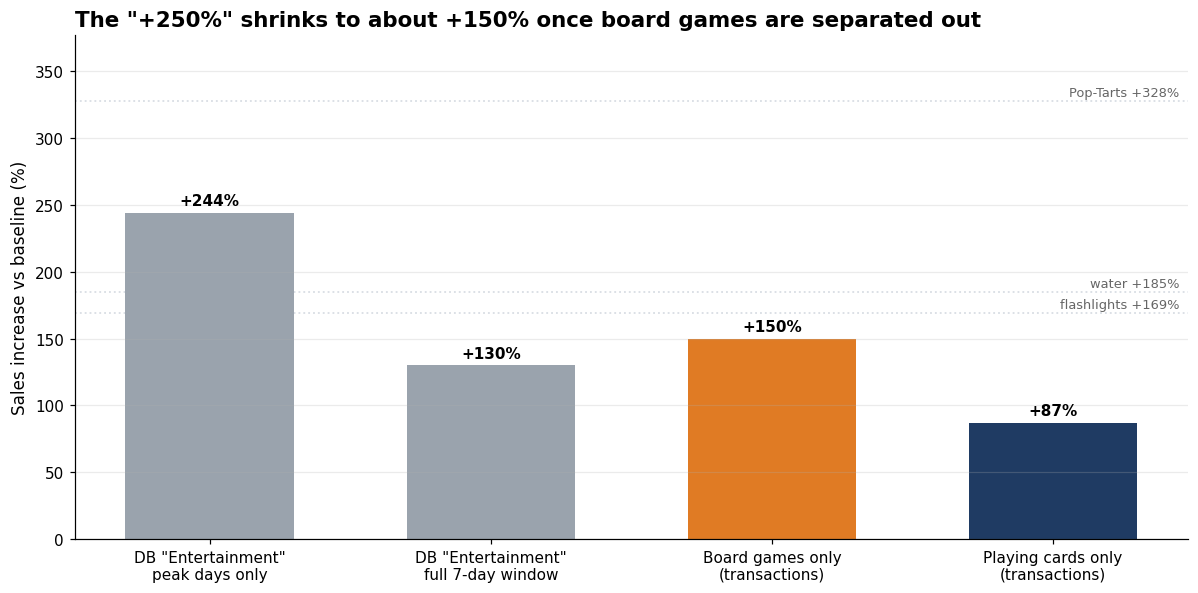

In [13]:
# CHART Q5a:
evidence = pd.Series({
    'DB "Entertainment"\npeak days only': db_compare.loc['Entertainment', 'peak days Sept 24–25 vs baseline (%)'],
    'DB "Entertainment"\nfull 7-day window': db_compare.loc['Entertainment', '7-day surge vs baseline (%)'],
    'Board games only\n(transactions)': lumping.loc['Board games (Monopoly)'].iloc[0],
    'Playing cards only\n(transactions)': lumping.loc['Playing cards'].iloc[0],
})
benchmarks = surge_pct(tx.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = [GREY, GREY, ORANGE, NAVY]
bars = ax.bar(evidence.index, evidence.values, color=colors, width=0.6)
ax.bar_label(bars, labels=[f'+{v:.0f}%' for v in evidence.values], padding=3, fontsize=10, fontweight='bold')
for sku, name in [('WTR-24', 'water'), ('LED-FLASH', 'flashlights'), ('POPTART-STRAW', 'Pop-Tarts')]:
    ax.axhline(benchmarks[sku], color=LIGHT, lw=1.2, ls=':', zorder=0)
    ax.text(3.45, benchmarks[sku] + 4, f'{name} +{benchmarks[sku]:.0f}%', ha='right', fontsize=8.5, color='#666')
ax.set_title('The "+250%" shrinks to about +150% once board games are separated out')
ax.set_ylabel('Sales increase vs baseline (%)')
ax.set_ylim(0, max(evidence.max(), benchmarks['POPTART-STRAW']) * 1.15)
ax.grid(axis='x', visible=False)
ax.title.set_fontsize(12.5)
plt.tight_layout()
plt.show()

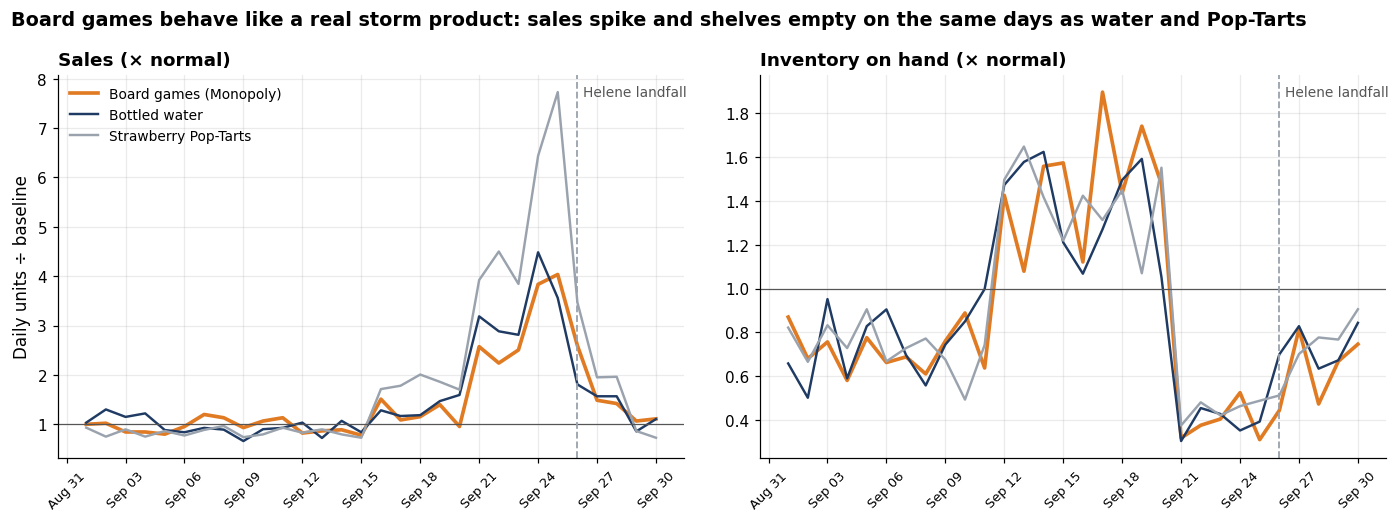

In [14]:
# CHART Q5b:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)

units = tx.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0)[list(compare_skus)].rename(columns=compare_skus)
units_idx = units / units[in_window(units.index, BASELINE_START, BASELINE_END)].mean()
for col, c in zip(units_idx.columns, [ORANGE, NAVY, GREY]):
    axes[0].plot(units_idx.index, units_idx[col], color=c, lw=2.4 if c == ORANGE else 1.6, label=col)
axes[0].axhline(1, color='#555', lw=0.8)
axes[0].set_title('Sales (× normal)', fontsize=12)
axes[0].set_ylabel('Daily units ÷ baseline')

inv_idx = inv_compare / inv_compare[in_window(inv_compare.index, BASELINE_START, BASELINE_END)].mean()
for col, c in zip(inv_idx.columns, [ORANGE, NAVY, GREY]):
    axes[1].plot(inv_idx.index, inv_idx[col], color=c, lw=2.4 if c == ORANGE else 1.6, label=col)
axes[1].axhline(1, color='#555', lw=0.8)
axes[1].set_title('Inventory on hand (× normal)', fontsize=12)

for ax in axes:
    mark_landfall(ax)
    format_dates(ax)
    ax.tick_params(axis='x', rotation=45, labelsize=8.5)
axes[0].legend(loc='upper left', fontsize=9)
fig.suptitle('Board games behave like a real storm product: sales spike and shelves empty on the same days as water and Pop-Tarts',
             x=0.01, ha='left', fontsize=12.5, fontweight='bold')
plt.tight_layout()
plt.show()

### Q5 Answer and Recommendation

**Verdict:** The +250% was an overstatement of what actually occurred. The true board-game lift is about **+150% (2.5x normal)**.

**We know this demand was real because:**
1. Monopoly sales rose about 2.5x, similar to the increases in battery sales (**2.49x**) and flashlight sales (**2.69x**);
2. the increase happened in **all 12 stores**; and
3. board-game inventory levels began dropping on **Sept. 21**, the same day sales jumped, just like water and Pop-Tarts. This means there was **no** reporting delay.

**The +250% was inflated in three ways:**
1. The window chosen made it appear as though sales increased by **+244%** (peak days only), when over the full week they really only increased by **+130%**;
2. playing card sales were included within the "Entertainment" category, and those items increased by only **+87%**; and
3. Monopoly has **three SKUs**, and **four** inventory codes could not be matched to any product.

**Recommendation:** I would say yes, that Walmart should have an excess of board games in each Florida store location, however this excess should be approximately **2.5 times normal sales volume** rather than 3.5 times as suggested in the prompt. The excess of board games should be placed at all locations throughout Florida (**as Q4 demonstrated demand increases across the entire state**) 5-7 days prior to the projected landfall. Since board games do not "go bad" or expire, if we overstock it would simply mean marking down our inventory of board games after the storm, which is a less costly approach than having to throw away product. Prior to the next storm, I believe Walmart should fix the SKU mapping and separate the board game and playing card categories from one another, allowing the dashboard to report the true amount of board games.

**Limitations/Assumptions:** This is based upon information related to a single storm and synthetic data. Since the database table scales significantly larger than the transaction file, we were forced to compare percent changes, because comparing raw units was not possible.